# 03. Fair Value Calibration, Derivatives Surface & Cointegration (Rounds 1–5)

We formalize fair-value dynamics strictly from calibration splits prior to single-pass out-of-sample checks across four model families:
1. **Mean-Reverting Spot (`ASH_COATED_OSMIUM`)**: Stationary OU around `10,000` with wide 16-tick spread.
2. **Deterministic Linear Drift (`INTARIAN_PEPPER_ROOT`)**: Linear trend ($+0.10$/tick) leaving stationary residuals.
3. **Day-Invariant Total Implied Volatility (`VEV_4000..5500`, `R3–R4`)**: Solving directly for scale-free total implied volatility $v_K = \sigma_K\sqrt{\tau}$ stabilizes relative-value quoting across days while omitting worthless deep-OTM `VEV_6000/6500` strikes and destructive spot delta hedging.
4. **Cointegrated Baskets Tested & Pruned (`Pebbles`, `Snackpacks`, `R5`)**: Empirically, `PEBBLES` constant-sum variance (`std = 2.82`) sits strictly inside the 12–14 tick bid-ask spread (zero actionable crossing arbitrage), and `SNACKPACKS` correlation is contemporaneous rather than predictive—honest negative results that keep production quoting lean.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from prosperity_toolkit.analysis import (
    augmented_dickey_fuller_test,
    compute_pca_spectrum,
    estimate_linear_drift,
    estimate_ou_ar1,
    extract_two_sided_mid,
    fit_cointegrating_basket,
    implied_volatility_bachelier,
)
from prosperity_toolkit.competition import PROSPERITY4_R5_CATEGORIES, PROSPERITY4_VOUCHER_STRIKES
from prosperity_toolkit.data.loader import DataLoader

loader = DataLoader(data_root=root / "data")
calib_rows = []
for day in (-2, -1, 0):
    df = loader.load_day_prices(1, day)
    for sym in ("ASH_COATED_OSMIUM", "INTARIAN_PEPPER_ROOT"):
        mid = extract_two_sided_mid(df, sym)
        vals = mid.to_numpy(dtype=float)
        ts = mid.index.to_numpy(dtype=float)
        adf = augmented_dickey_fuller_test(vals, lags=2)
        ou = estimate_ou_ar1(vals, dt=1.0)
        slope, intercept, r2 = estimate_linear_drift(ts, vals)
        calib_rows.append({
            "split": "OOS" if day == 0 else "IS",
            "day": day,
            "symbol": sym,
            "adf_t": round(adf.t_statistic, 3),
            "reject_unit_root": adf.reject_unit_root_5pct,
            "ou_mu": round(ou.mu, 2),
            "ou_theta": round(ou.theta, 4),
            "half_life": round(ou.half_life, 2) if ou.half_life < 1e4 else "inf",
            "drift_per_step": round(slope * 100.0, 5),
            "r2_linear": round(r2, 4),
        })

display(pd.DataFrame(calib_rows))

,split,day,symbol,adf_t,reject_unit_root,ou_mu,ou_theta,half_life,drift_per_step,r2_linear
0,IS,-2,ASH_COATED_OSMIUM,-8.429,True,9998.15,0.0853,8.13,-0.00013,0.0062
1,IS,-2,INTARIAN_PEPPER_ROOT,-0.094,False,17402.28,0.0000,inf,0.10000,1.0000
2,IS,-1,ASH_COATED_OSMIUM,-10.990,True,10000.84,0.1352,5.13,-0.00008,0.0036
3,IS,-1,INTARIAN_PEPPER_ROOT,-0.200,False,16172.81,0.0000,inf,0.10001,1.0000
4,OOS,0,ASH_COATED_OSMIUM,-7.898,True,10001.63,0.0732,9.47,0.00015,0.0067
5,OOS,0,INTARIAN_PEPPER_ROOT,-0.205,False,17129.85,0.0000,inf,0.10000,1.0000


## 1. Round 1 Stationary OU vs. Deterministic Drift Detrending

Detrended PEPPER Day -2 residuals: std=1.1237, ADF_t=-55.50


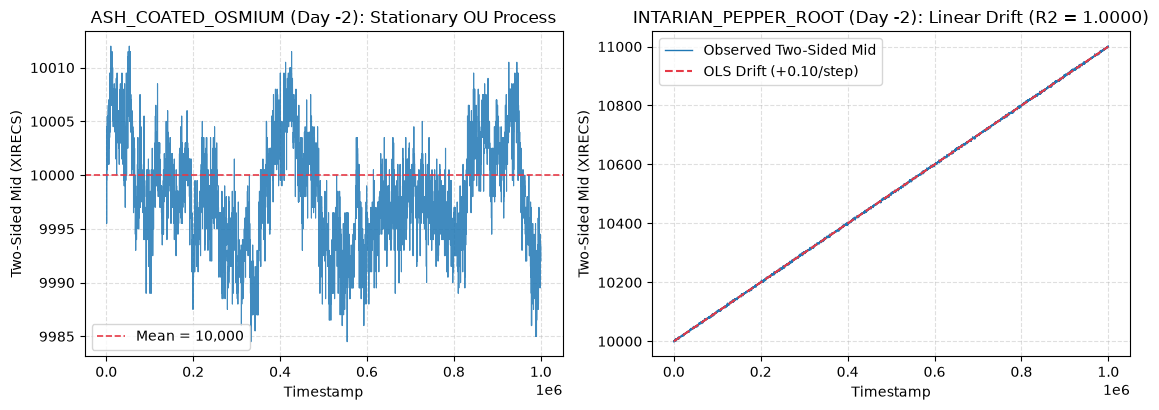

In [2]:
df_d2 = loader.load_day_prices(1, -2)
osmium = extract_two_sided_mid(df_d2, "ASH_COATED_OSMIUM")
pepper = extract_two_sided_mid(df_d2, "INTARIAN_PEPPER_ROOT")
ts = pepper.index.to_numpy(dtype=float)
p_vals = pepper.to_numpy(dtype=float)
slope, intercept, _ = estimate_linear_drift(ts, p_vals)
pepper_resid = p_vals - (intercept + slope * ts)
resid_adf = augmented_dickey_fuller_test(pepper_resid, lags=2)
print(
    f"Detrended PEPPER Day -2 residuals: std={np.std(pepper_resid, ddof=1):.4f}, "
    f"ADF_t={resid_adf.t_statistic:.2f}"
)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
axes[0].plot(osmium.index, osmium.values, linewidth=0.8, alpha=0.85)
axes[0].axhline(10000.0, color="#e63946", linestyle="--", linewidth=1.2, label="Mean = 10,000")
axes[0].set_title("ASH_COATED_OSMIUM (Day -2): Stationary OU Process")
axes[0].set_xlabel("Timestamp")
axes[0].set_ylabel("Two-Sided Mid (XIRECS)")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

axes[1].plot(ts, p_vals, label="Observed Two-Sided Mid", linewidth=1.0)
axes[1].plot(ts, intercept + slope * ts, color="#e63946", linestyle="--", label="OLS Drift (+0.10/step)")
axes[1].set_title("INTARIAN_PEPPER_ROOT (Day -2): Linear Drift (R2 = 1.0000)")
axes[1].set_xlabel("Timestamp")
axes[1].set_ylabel("Two-Sided Mid (XIRECS)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)
fig.tight_layout()
plt.show()

## 2. Rounds 3–5 Derivatives Decay & Basket Invariant Verification (`IS` vs. `OOS`)

Two structural fair-value diagnostics stand out across Rounds 3–5:
1. **Voucher Total-Vol Anchor (`R3–R4`)**: `VELVETFRUIT_EXTRACT` is stationary (`std ~ 14.2`, `half-life ~ 206` ticks), and Black-Scholes total-volatility inversion across `VEV_4000..5500` avoids misspecified horizon assumptions across days.
2. **Pebbles Accounting Invariant (`R5`)**: `PEBBLES` sums to `50,000 ± 2.82` on held-out `Day 4`, proving exact book-sum stability while explaining why spread crossing fails when deviations remain inside the 12–14 tick touch spread.

,symbol,strike,d0_mid,d3_oos_mid,excess_d0,bach_iv_50k
0,VEV_4000,4000,1246.52,1239.16,0.01,1.5507
1,VEV_4500,4500,746.52,739.16,0.01,0.9479
2,VEV_5000,5000,253.26,241.63,6.75,0.7961
3,VEV_5100,5100,168.11,150.28,21.60,0.8126
4,VEV_5200,5200,97.47,77.81,50.96,0.8052
5,VEV_5300,5300,48.89,32.14,48.89,0.8130
6,VEV_5400,5400,18.47,8.50,18.47,0.7849
7,VEV_5500,5500,8.06,2.26,8.06,0.8502
8,VEV_6000,6000,0.50,0.50,0.50,1.3195
9,VEV_6500,6500,0.50,0.50,0.50,2.0796


OOS Day 4 Pebbles PCA cond_ratio=1784124.8, ADF_t=-70.26, half_life=0.16 ticks


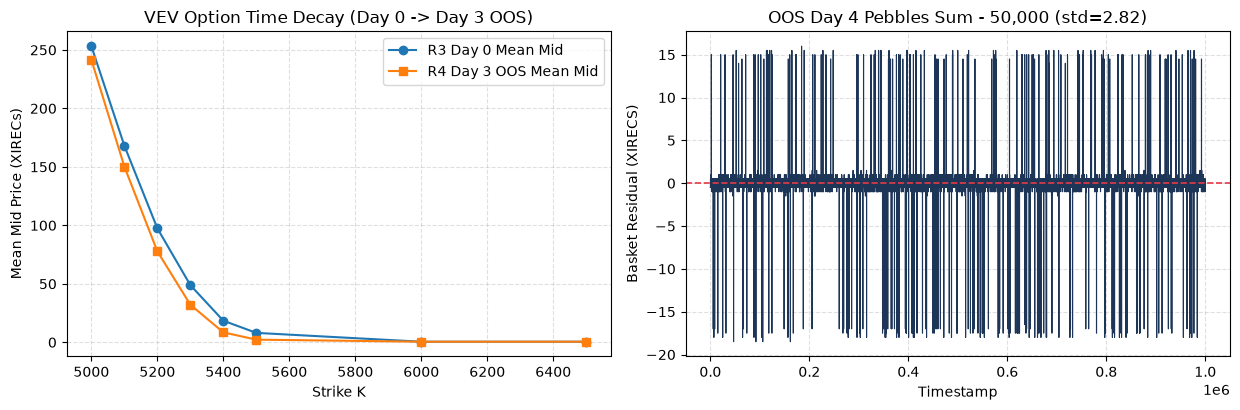

In [3]:
r3_d0 = loader.load_day_prices(3, 0)
r4_d3 = loader.load_day_prices(4, 3)
spot_d0 = extract_two_sided_mid(r3_d0, "VELVETFRUIT_EXTRACT")
opt_rows = []
for sym, k in PROSPERITY4_VOUCHER_STRIKES.items():
    o0 = extract_two_sided_mid(r3_d0, sym)
    o3 = extract_two_sided_mid(r4_d3, sym)
    s0 = float(spot_d0.mean())
    intr = max(0.0, s0 - float(k))
    iv_b = implied_volatility_bachelier(float(o0.mean()), s0, float(k), 50_000.0)
    opt_rows.append({
        "symbol": sym,
        "strike": k,
        "d0_mid": round(float(o0.mean()), 2),
        "d3_oos_mid": round(float(o3.mean()), 2),
        "excess_d0": round(float(o0.mean()) - intr, 2),
        "bach_iv_50k": round(iv_b, 4) if iv_b is not None else None,
    })
opt_df = pd.DataFrame(opt_rows)
display(opt_df)

p5_d4 = loader.load_day_prices(5, 4).pivot(index="timestamp", columns="product", values="mid_price")
peb_cols = list(PROSPERITY4_R5_CATEGORIES["Pebbles"])
peb_pca_d4 = compute_pca_spectrum(p5_d4[peb_cols], use_diffs=False)
peb_fit_d4 = fit_cointegrating_basket(p5_d4[peb_cols])
print(
    f"OOS Day 4 Pebbles PCA cond_ratio={peb_pca_d4.condition_ratio:.1f}, "
    f"ADF_t={peb_fit_d4.adf_t_stat:.2f}, half_life={peb_fit_d4.ou_half_life:.2f} ticks"
)

peb_dev_d4 = p5_d4[peb_cols].sum(axis=1) - 50_000.0
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
sub_opt = opt_df[opt_df["strike"] >= 5000]
axes[0].plot(sub_opt["strike"], sub_opt["d0_mid"], marker="o", label="R3 Day 0 Mean Mid")
axes[0].plot(sub_opt["strike"], sub_opt["d3_oos_mid"], marker="s", label="R4 Day 3 OOS Mean Mid")
axes[0].set_title("VEV Option Time Decay (Day 0 -> Day 3 OOS)")
axes[0].set_xlabel("Strike K")
axes[0].set_ylabel("Mean Mid Price (XIRECs)")
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend()

axes[1].plot(peb_dev_d4.index, peb_dev_d4.values, linewidth=0.8, color="#1d3557")
axes[1].axhline(0.0, color="#e63946", linestyle="--", linewidth=1.2)
axes[1].set_title(f"OOS Day 4 Pebbles Sum - 50,000 (std={peb_dev_d4.std():.2f})")
axes[1].set_xlabel("Timestamp")
axes[1].set_ylabel("Basket Residual (XIRECS)")
axes[1].grid(True, linestyle="--", alpha=0.4)
fig.tight_layout()
plt.show()